In [0]:
import pandas as pd
import numpy as np

In [0]:
stockouts=spark.table("workspace.pandas.fresh_mart_dataset_stockouts").toPandas()

display(stockouts)

stockout_id,store_id,date,category,duration_hours,note
SO0020,ST1039,2025-09-06,Household Cleaning,9,Replenishment gap - weekend delivery missed
SO0104,ST1040,2025-09-06,Household Cleaning,6,Replenishment gap - weekend delivery missed
SO0082,ST1006,2025-09-07,Household Cleaning,9,Replenishment gap - weekend delivery missed
SO0001,ST1024,2025-09-07,Household Cleaning,7,Replenishment gap - weekend delivery missed
SO0021,ST1039,2025-09-07,Household Cleaning,10,Replenishment gap - weekend delivery missed
SO0105,ST1040,2025-09-07,Household Cleaning,9,Replenishment gap - weekend delivery missed
SO0065,ST1041,2025-09-07,Household Cleaning,7,Replenishment gap - weekend delivery missed
SO0041,ST1002,2025-09-13,Household Cleaning,10,Replenishment gap - weekend delivery missed
SO0106,ST1040,2025-09-13,Household Cleaning,6,Replenishment gap - weekend delivery missed
SO0066,ST1041,2025-09-13,Household Cleaning,9,Replenishment gap - weekend delivery missed


In [0]:
#Check dataset size
stockouts.shape

(119, 6)

In [0]:
#Check column names
stockouts.columns

Index(['stockout_id', 'store_id', 'date', 'category', 'duration_hours',
       'note'],
      dtype='object')

In [0]:
#Check data types
stockouts.dtypes

stockout_id       object
store_id          object
date              object
category          object
duration_hours     int64
note              object
dtype: object

In [0]:
 # Check whether every stockout has a unique stockout ID
stockouts["stockout_id"].nunique()

119

In [0]:
# Count how many stockout records each store has
stockouts["store_id"].value_counts() 

store_id
ST1002    24
ST1006    22
ST1039    21
ST1024    19
ST1041    17
ST1040    16
Name: count, dtype: int64

In [0]:
# Show the stockout records with their store IDs
stockouts[["stockout_id", "store_id", "date", "category", "note"]]

,stockout_id,store_id,date,category,note
0,SO0020,ST1039,2025-09-06,Household Cleaning,Replenishment gap - weekend delivery missed
1,SO0104,ST1040,2025-09-06,Household Cleaning,Replenishment gap - weekend delivery missed
2,SO0082,ST1006,2025-09-07,Household Cleaning,Replenishment gap - weekend delivery missed
3,SO0001,ST1024,2025-09-07,Household Cleaning,Replenishment gap - weekend delivery missed
4,SO0021,ST1039,2025-09-07,Household Cleaning,Replenishment gap - weekend delivery missed
...,...,...,...,...,...
114,SO0081,ST1041,2025-12-14,Household Cleaning,Replenishment gap - weekend delivery missed
115,SO0064,ST1002,2025-12-20,Household Cleaning,Replenishment gap - weekend delivery missed
116,SO0103,ST1006,2025-12-20,Household Cleaning,Replenishment gap - weekend delivery missed
117,SO0040,ST1039,2025-12-20,Household Cleaning,Replenishment gap - weekend delivery missed


In [0]:
 # Show the stockout records with their store IDs
stockouts[["stockout_id", "store_id", "date", "category", "note"]]

,stockout_id,store_id,date,category,note
0,SO0020,ST1039,2025-09-06,Household Cleaning,Replenishment gap - weekend delivery missed
1,SO0104,ST1040,2025-09-06,Household Cleaning,Replenishment gap - weekend delivery missed
2,SO0082,ST1006,2025-09-07,Household Cleaning,Replenishment gap - weekend delivery missed
3,SO0001,ST1024,2025-09-07,Household Cleaning,Replenishment gap - weekend delivery missed
4,SO0021,ST1039,2025-09-07,Household Cleaning,Replenishment gap - weekend delivery missed
...,...,...,...,...,...
114,SO0081,ST1041,2025-12-14,Household Cleaning,Replenishment gap - weekend delivery missed
115,SO0064,ST1002,2025-12-20,Household Cleaning,Replenishment gap - weekend delivery missed
116,SO0103,ST1006,2025-12-20,Household Cleaning,Replenishment gap - weekend delivery missed
117,SO0040,ST1039,2025-12-20,Household Cleaning,Replenishment gap - weekend delivery missed


In [0]:
#let's see how many different notes we  actually have
# Check all the different reasons recorded in the stockout notes.
# This helps us understand what is causing stockouts in the FreshMart stores.
# If we find only one type of note, it means the dataset is identifying

stockouts["note"].unique()

array(['Replenishment gap - weekend delivery missed'], dtype=object)

In [0]:
#Then we can count how many times each note appears
#How many stockout records have each reason?
# This helps us determine whether a particular stockout reason is isolated
# or occurs repeatedly across the business.

stockouts["note"].value_counts()

note
Replenishment gap - weekend delivery missed    119
Name: count, dtype: int64

In [0]:
# check if we have any missing notes in the dataset
#Check how many stockout records do not contain a note.
# Missing notes would mean that we have a stockout event but no explanation
# recorded for why it happened.

stockouts["note"].isna().sum()


np.int64(0)

In [0]:
## Group the stockout records by product category and then count
# the different notes within each category.
# This helps us identify which product categories are affected by the note  problem.

stockouts["note"].count()

np.int64(119)

In [0]:
#On which dates were these stockout reasons recorded?
#  Count the number of stockout notes recorded on each date.
# This helps us identify whether stockout incidents are concentrated on particular days.

stockouts.groupby("date")["note"].value_counts()

date        note                                       
2025-09-06  Replenishment gap - weekend delivery missed    2
2025-09-07  Replenishment gap - weekend delivery missed    5
2025-09-13  Replenishment gap - weekend delivery missed    3
2025-09-14  Replenishment gap - weekend delivery missed    2
2025-09-20  Replenishment gap - weekend delivery missed    3
2025-09-21  Replenishment gap - weekend delivery missed    3
2025-09-27  Replenishment gap - weekend delivery missed    5
2025-09-28  Replenishment gap - weekend delivery missed    3
2025-10-04  Replenishment gap - weekend delivery missed    6
2025-10-05  Replenishment gap - weekend delivery missed    4
2025-10-11  Replenishment gap - weekend delivery missed    6
2025-10-12  Replenishment gap - weekend delivery missed    5
2025-10-18  Replenishment gap - weekend delivery missed    1
2025-10-19  Replenishment gap - weekend delivery missed    4
2025-10-25  Replenishment gap - weekend delivery missed    4
2025-10-26  Replenishment gap

In [0]:
#Count the stockout notes for each store.
# This helps identify whether the replenishment problem is widespread or concentrated in particular stores.

stockouts.groupby("store_id")["note"].value_counts()

store_id  note                                       
ST1002    Replenishment gap - weekend delivery missed    24
ST1006    Replenishment gap - weekend delivery missed    22
ST1024    Replenishment gap - weekend delivery missed    19
ST1039    Replenishment gap - weekend delivery missed    21
ST1040    Replenishment gap - weekend delivery missed    16
ST1041    Replenishment gap - weekend delivery missed    17
Name: count, dtype: int64

In [0]:
stockouts["date"] = pd.to_datetime(stockouts["date"])
stockouts["year"] = stockouts["date"].dt.year
stockouts["month"] = stockouts["date"].dt.month
stockouts["day"] = stockouts["date"].dt.day
stockouts["weekday"] = stockouts["date"].dt.weekday


display(stockouts)

stockout_id,store_id,date,category,duration_hours,note,year,month,day,weekday
SO0020,ST1039,2025-09-06T00:00:00.000Z,Household Cleaning,9,Replenishment gap - weekend delivery missed,2025,9,6,5
SO0104,ST1040,2025-09-06T00:00:00.000Z,Household Cleaning,6,Replenishment gap - weekend delivery missed,2025,9,6,5
SO0082,ST1006,2025-09-07T00:00:00.000Z,Household Cleaning,9,Replenishment gap - weekend delivery missed,2025,9,7,6
SO0001,ST1024,2025-09-07T00:00:00.000Z,Household Cleaning,7,Replenishment gap - weekend delivery missed,2025,9,7,6
SO0021,ST1039,2025-09-07T00:00:00.000Z,Household Cleaning,10,Replenishment gap - weekend delivery missed,2025,9,7,6
SO0105,ST1040,2025-09-07T00:00:00.000Z,Household Cleaning,9,Replenishment gap - weekend delivery missed,2025,9,7,6
SO0065,ST1041,2025-09-07T00:00:00.000Z,Household Cleaning,7,Replenishment gap - weekend delivery missed,2025,9,7,6
SO0041,ST1002,2025-09-13T00:00:00.000Z,Household Cleaning,10,Replenishment gap - weekend delivery missed,2025,9,13,5
SO0106,ST1040,2025-09-13T00:00:00.000Z,Household Cleaning,6,Replenishment gap - weekend delivery missed,2025,9,13,5
SO0066,ST1041,2025-09-13T00:00:00.000Z,Household Cleaning,9,Replenishment gap - weekend delivery missed,2025,9,13,5


In [0]:
 # 1. Convert transaction_date into a proper date
stockouts["date"] = pd.to_datetime(stockouts["date"])

# 2. Extract the year
stockouts["year"] = stockouts["date"].dt.year

# 3. Extract the month number
stockouts["month"] = stockouts["date"].dt.month

# 4. Extract the day of the month
stockouts["day"] = stockouts["date"].dt.day

# 5. Extract the day name
stockouts["day_of_week"] = stockouts["date"].dt.day_name()

# 6. Create a month-year column
stockouts["month_year"] = stockouts["date"].dt.to_period("M")

# 7. Display the result
display(stockouts)

stockout_id,store_id,date,category,duration_hours,note,year,month,day,weekday,day_of_week,month_year
SO0020,ST1039,2025-09-06T00:00:00.000Z,Household Cleaning,9,Replenishment gap - weekend delivery missed,2025,9,6,5,Saturday,668
SO0104,ST1040,2025-09-06T00:00:00.000Z,Household Cleaning,6,Replenishment gap - weekend delivery missed,2025,9,6,5,Saturday,668
SO0082,ST1006,2025-09-07T00:00:00.000Z,Household Cleaning,9,Replenishment gap - weekend delivery missed,2025,9,7,6,Sunday,668
SO0001,ST1024,2025-09-07T00:00:00.000Z,Household Cleaning,7,Replenishment gap - weekend delivery missed,2025,9,7,6,Sunday,668
SO0021,ST1039,2025-09-07T00:00:00.000Z,Household Cleaning,10,Replenishment gap - weekend delivery missed,2025,9,7,6,Sunday,668
SO0105,ST1040,2025-09-07T00:00:00.000Z,Household Cleaning,9,Replenishment gap - weekend delivery missed,2025,9,7,6,Sunday,668
SO0065,ST1041,2025-09-07T00:00:00.000Z,Household Cleaning,7,Replenishment gap - weekend delivery missed,2025,9,7,6,Sunday,668
SO0041,ST1002,2025-09-13T00:00:00.000Z,Household Cleaning,10,Replenishment gap - weekend delivery missed,2025,9,13,5,Saturday,668
SO0106,ST1040,2025-09-13T00:00:00.000Z,Household Cleaning,6,Replenishment gap - weekend delivery missed,2025,9,13,5,Saturday,668
SO0066,ST1041,2025-09-13T00:00:00.000Z,Household Cleaning,9,Replenishment gap - weekend delivery missed,2025,9,13,5,Saturday,668


In [0]:
 
import pandas as pd

# Create a copy of the original Stockouts dataset
stockouts_clean = stockouts.copy()

# 1. Remove unnecessary spaces from text columns
text_columns = [
    "stockout_id",
    "store_id",
    "category",
    "note"
]

for column in text_columns:
    stockouts_clean[column] = (
        stockouts_clean[column].str.strip()
    )

# 2. Convert date into datetime format
stockouts_clean["date"] = pd.to_datetime(
    stockouts_clean["date"],
    errors="coerce"
)

# 3. Create a month column
stockouts_clean["month"] = (
    stockouts_clean["date"].dt.month_name()
)

# 4. Create a day of the week column
stockouts_clean["day_of_week"] = (
    stockouts_clean["date"].dt.day_name()
)

# 5. Classify each date as weekday or weekend
stockouts_clean["shopping_period"] = (
    stockouts_clean["date"].dt.dayofweek
    .apply(lambda day: "Weekend" if day >= 5 else "Weekday")
)

# Display the cleaned dataset
stockouts_clean.head()


,stockout_id,store_id,date,category,duration_hours,note,year,month,day,weekday,day_of_week,month_year,shopping_period
0,SO0020,ST1039,2025-09-06,Household Cleaning,9,Replenishment gap - weekend delivery missed,2025,September,6,5,Saturday,2025-09,Weekend
1,SO0104,ST1040,2025-09-06,Household Cleaning,6,Replenishment gap - weekend delivery missed,2025,September,6,5,Saturday,2025-09,Weekend
2,SO0082,ST1006,2025-09-07,Household Cleaning,9,Replenishment gap - weekend delivery missed,2025,September,7,6,Sunday,2025-09,Weekend
3,SO0001,ST1024,2025-09-07,Household Cleaning,7,Replenishment gap - weekend delivery missed,2025,September,7,6,Sunday,2025-09,Weekend
4,SO0021,ST1039,2025-09-07,Household Cleaning,10,Replenishment gap - weekend delivery missed,2025,September,7,6,Sunday,2025-09,Weekend


In [0]:
 
# Check the dataset dimensions
print("Dataset shape:", stockouts_clean.shape)

# Check missing values
print("\nMissing values:")
print(stockouts_clean.isnull().sum())

# Check duplicate records
print("\nDuplicate rows:")
print(stockouts_clean.duplicated().sum())

# Check stockout duration
print("\nDuration statistics:")
print(stockouts_clean["duration_hours"].describe())

# Check the new month field
print("\nStockouts by month:")
print(stockouts_clean["month"].value_counts())

# Check weekday and weekend distribution
print("\nWeekday vs Weekend:")
print(stockouts_clean["shopping_period"].value_counts())


Dataset shape: (119, 13)

Missing values:
stockout_id        0
store_id           0
date               0
category           0
duration_hours     0
note               0
year               0
month              0
day                0
weekday            0
day_of_week        0
month_year         0
shopping_period    0
dtype: int64

Duplicate rows:
0

Duration statistics:
count    119.000000
mean       7.588235
std        1.648892
min        5.000000
25%        6.000000
50%        8.000000
75%        9.000000
max       10.000000
Name: duration_hours, dtype: float64

Stockouts by month:
month
November     39
October      33
September    26
December     21
Name: count, dtype: int64

Weekday vs Weekend:
shopping_period
Weekend    119
Name: count, dtype: int64


In [0]:
 
# Create a copy of the cleaned Stockouts dataset
stockouts_clean = stockouts.copy()

# Convert date to datetime
stockouts_clean["date"] = pd.to_datetime(
    stockouts_clean["date"]
)

# Create month
stockouts_clean["month"] = (
    stockouts_clean["date"].dt.month_name()
)

# Create day of the week
stockouts_clean["day_of_week"] = (
    stockouts_clean["date"].dt.day_name()
)

# Classify weekday and weekend
stockouts_clean["shopping_period"] = (
    stockouts_clean["date"].dt.dayofweek
    .apply(lambda day: "Weekend" if day >= 5 else "Weekday")
)

# Group stockout duration
stockouts_clean["duration_band"] = pd.cut(
    stockouts_clean["duration_hours"],
    bins=[0, 5, 8, 24],
    labels=["Short", "Medium", "Long"],
    include_lowest=True
)

# Display the new columns
stockouts_clean[
    [
        "date",
        "month",
        "day_of_week",
        "shopping_period",
        "duration_hours",
        "duration_band"
    ]
].head(10)


,date,month,day_of_week,shopping_period,duration_hours,duration_band
0,2025-09-06,September,Saturday,Weekend,9,Long
1,2025-09-06,September,Saturday,Weekend,6,Medium
2,2025-09-07,September,Sunday,Weekend,9,Long
3,2025-09-07,September,Sunday,Weekend,7,Medium
4,2025-09-07,September,Sunday,Weekend,10,Long
5,2025-09-07,September,Sunday,Weekend,9,Long
6,2025-09-07,September,Sunday,Weekend,7,Medium
7,2025-09-13,September,Saturday,Weekend,10,Long
8,2025-09-13,September,Saturday,Weekend,6,Medium
9,2025-09-13,September,Saturday,Weekend,9,Long


In [0]:
 
import pandas as pd
import numpy as np

# Make a copy of the Transactions dataset
transactions_analysis = transactions_df.copy()

# Convert transaction_date into datetime format
transactions_analysis["transaction_date"] = pd.to_datetime(
    transactions_analysis["transaction_date"],
    errors="coerce"
)

# Create month
transactions_analysis["month"] = (
    transactions_analysis["transaction_date"].dt.month_name()
)

# Create year and month
transactions_analysis["year_month"] = (
    transactions_analysis["transaction_date"].dt.to_period("M")
)

# Create day of the week from the date
transactions_analysis["day_of_week"] = (
    transactions_analysis["transaction_date"].dt.day_name()
)

# Classify transactions as Weekday or Weekend
transactions_analysis["shopping_period"] = np.where(
    transactions_analysis["transaction_date"].dt.dayofweek >= 5,
    "Weekend",
    "Weekday"
)

# Group baskets by number of items
transactions_analysis["basket_size_band"] = pd.cut(
    transactions_analysis["num_items"],
    bins=[0, 5, 15, float("inf")],
    labels=["Small", "Medium", "Large"]
)

# Standardise loyalty values
transactions_analysis["is_loyalty_member"] = (
    transactions_analysis["is_loyalty_member"]
    .astype("string")
    .str.strip()
    .str.title()
)

# Create loyalty segment
transactions_analysis["loyalty_segment"] = (
    transactions_analysis["is_loyalty_member"]
    .map({
        "Yes": "Loyalty",
        "No": "Non-loyalty"
    })
    .fillna("Unknown")
)

# Display the new fields
transactions_analysis[
    [
        "transaction_date",
        "month",
        "year_month",
        "day_of_week",
        "shopping_period",
        "num_items",
        "basket_size_band",
        "is_loyalty_member",
        "loyalty_segment"
    ]
].head(10)


,transaction_date,month,year_month,day_of_week,shopping_period,num_items,basket_size_band,is_loyalty_member,loyalty_segment
0,2025-01-01,January,2025-01,Wednesday,Weekday,25,Large,No,Non-loyalty
1,2025-01-01,January,2025-01,Wednesday,Weekday,32,Large,Yes,Loyalty
2,2025-01-01,January,2025-01,Wednesday,Weekday,19,Large,No,Non-loyalty
3,2025-01-01,January,2025-01,Wednesday,Weekday,24,Large,Yes,Loyalty
4,2025-01-01,January,2025-01,Wednesday,Weekday,1,Small,Yes,Loyalty
5,2025-01-01,January,2025-01,Wednesday,Weekday,20,Large,No,Non-loyalty
6,2025-01-01,January,2025-01,Wednesday,Weekday,27,Large,Yes,Loyalty
7,2025-01-01,January,2025-01,Wednesday,Weekday,20,Large,Yes,Loyalty
8,2025-01-01,January,2025-01,Wednesday,Weekday,3,Small,No,Non-loyalty
9,2025-01-01,January,2025-01,Wednesday,Weekday,13,Medium,Yes,Loyalty


In [0]:
 
# Load the source datasets needed for this join
# (the Transactions and Stores tables are not loaded anywhere else in this notebook)
transactions_df = spark.table("workspace.pandas.fresh_mart_dataset_1").toPandas()
stores_df = spark.table("workspace.pandas.fresh_mart_stores").toPandas()

# Join Transactions with Stores using store_id
analysis_df = transactions_analysis.merge(
    stores_df,
    on="store_id",
    how="left",
    validate="many_to_one"
)

# Check the combined dataset
print("Combined dataset shape:", analysis_df.shape)

# Check whether any transactions failed to match a store
print(
    "Transactions without a store match:",
    analysis_df["store_name"].isna().sum()
)

# Display selected columns
analysis_df[
    [
        "transaction_id",
        "store_name",
        "province",
        "store_format",
        "num_items",
        "basket_value_zar",
        "loyalty_segment",
        "shopping_period"
    ]
].head()


---------------------------------------------------------------------------
NameError                                 Traceback (most recent call last)
File <command-8175855199159264>, line 8
      5 stores_df = spark.table("workspace.pandas.fresh_mart_stores").toPandas()
      7 # Join Transactions with Stores using store_id
----> 8 analysis_df = transactions_analysis.merge(
      9     stores_df,
     10     on="store_id",
     11     how="left",
     12     validate="many_to_one"
     13 )
     15 # Check the combined dataset
     16 print("Combined dataset shape:", analysis_df.shape)

NameError: name 'transactions_analysis' is not defined

In [0]:
 #Analyse by time and shopping day

# Group transactions by month
monthly_analysis = (
    analysis_df.groupby("year_month")
    .agg(
        total_transactions=("transaction_id", "nunique"),
        average_items=("num_items", "mean"),
        average_basket_value=("basket_value_zar", "mean"),
        total_revenue=("basket_value_zar", "sum")
    )
    .reset_index()
)

# Display monthly results
monthly_analysis


,year_month,total_transactions,average_items,average_basket_value,total_revenue
0,2025-01,5175,14.751304,299.815422,1551544.81000000000005
1,2025-02,4840,14.542149,296.074686,1433001.47999999999981
2,2025-03,5321,14.261229,290.921718,1547994.45999999999990
3,2025-04,5167,13.938069,284.65893,1470832.69000000000125
4,2025-05,5415,14.033241,287.027993,1554256.57999999999954
5,2025-06,5191,13.844539,282.109287,1464429.31000000000114
6,2025-07,5276,13.351213,273.227735,1441549.52999999999982
7,2025-08,5599,13.218789,270.668391,1515472.32000000000222
8,2025-09,5262,13.032307,266.455532,1402089.01000000000074
9,2025-10,5581,12.542376,257.047036,1434579.50999999999971


In [0]:
 
# Compare weekday and weekend shopping
shopping_day_analysis = (
    analysis_df.groupby("shopping_period", observed=True)
    .agg(
        total_transactions=("transaction_id", "nunique"),
        average_items=("num_items", "mean"),
        average_basket_value=("basket_value_zar", "mean"),
        total_revenue=("basket_value_zar", "sum")
    )
    .reset_index()
)

# Display results
shopping_day_analysis


---------------------------------------------------------------------------
NameError                                 Traceback (most recent call last)
File <command-8175855199159289>, line 4
      2 # Compare weekday and weekend shopping
      3 shopping_day_analysis = (
----> 4     analysis_df.groupby("shopping_period", observed=True)
      5     .agg(
      6         total_transactions=("transaction_id", "nunique"),
      7         average_items=("num_items", "mean"),
      8         average_basket_value=("basket_value_zar", "mean"),
      9         total_revenue=("basket_value_zar", "sum")
     10     )
     11     .reset_index()
     12 )
     14 # Display results
     15 shopping_day_analysis

NameError: name 'analysis_df' is not defined

In [0]:
 
# Analyse performance by day of the week
weekday_analysis = (
    analysis_df.groupby("day_of_week", observed=True)
    .agg(
        total_transactions=("transaction_id", "nunique"),
        average_items=("num_items", "mean"),
        average_basket_value=("basket_value_zar", "mean")
    )
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ])
    .reset_index()
)

weekday_analysis


,day_of_week,total_transactions,average_items,average_basket_value
0,Monday,8235,13.298604,272.394131
1,Tuesday,8140,13.495332,275.449143
2,Wednesday,8418,13.510573,276.619989
3,Thursday,7843,13.474818,275.960113
4,Friday,8195,13.399146,273.461885
5,Saturday,11743,13.424934,274.720731
6,Sunday,11756,13.514716,276.521297


In [0]:
 #Test whether stockouts contributed to the decline

# Summarise stockouts by store and date
stockouts_daily = (
    stockouts_clean.groupby(["store_id", "date"])
    .agg(
        stockout_events=("stockout_id", "nunique"),
        total_stockout_hours=("duration_hours", "sum"),
        affected_categories=("category", "nunique")
    )
    .reset_index()
)

# Rename date so it matches the Transactions date column
stockouts_daily = stockouts_daily.rename(
    columns={"date": "transaction_date"}
)

# Join stockout information to transactions
task5_df = analysis_df.merge(
    stockouts_daily,
    on=["store_id", "transaction_date"],
    how="left",
    validate="many_to_one"
)

# Identify recorded stockout and non-stockout days
task5_df["stockout_events"] = (
    task5_df["stockout_events"].fillna(0)
)

task5_df["stockout_status"] = np.where(
    task5_df["stockout_events"] > 0,
    "Stockout day",
    "No recorded stockout"
)

# Compare basket performance
stockout_comparison = (
    task5_df.groupby("stockout_status")
    .agg(
        transactions=("transaction_id", "nunique"),
        average_items=("num_items", "mean"),
        average_basket_value=("basket_value_zar", "mean")
    )
    .reset_index()
)

stockout_comparison


,stockout_status,transactions,average_items,average_basket_value
0,No recorded stockout,63724,13.468473,275.490773
1,Stockout day,606,11.303630,232.244191


In [0]:
 
# Calculate overall FreshMart performance

baseline = pd.DataFrame({
    "Metric": [
        "Total transactions",
        "Average items per basket",
        "Average basket value (ZAR)",
        "Total revenue (ZAR)"
    ],
    "Value": [
        analysis_df["transaction_id"].nunique(),
        analysis_df["num_items"].mean(),
        analysis_df["basket_value_zar"].mean(),
        analysis_df["basket_value_zar"].sum()
    ]
})

# Display the baseline results
baseline


,Metric,Value
0,Total transactions,64330
1,Average items per basket,13.44808
2,Average basket value (ZAR),275.083383
3,Total revenue (ZAR),17696114.00000000000488


In [0]:
 
# Group transactions by loyalty segment
loyalty_analysis = (
    analysis_df.groupby("loyalty_segment", dropna=False)
    .agg(
        total_transactions=("transaction_id", "nunique"),
        average_items=("num_items", "mean"),
        average_basket_value=("basket_value_zar", "mean"),
        total_revenue=("basket_value_zar", "sum")
    )
    .reset_index()
)

# Calculate each segment's percentage of transactions
loyalty_analysis["transaction_share_pct"] = (
    loyalty_analysis["total_transactions"]
    / loyalty_analysis["total_transactions"].sum()
) * 100

# Display results
loyalty_analysis.round(2)


,loyalty_segment,total_transactions,average_items,average_basket_value,total_revenue,transaction_share_pct
0,Loyalty,28656,14.43,294.119563,8428290.20000000000119,44.55
1,Non-loyalty,35674,12.66,259.792112,9267823.80000000000369,55.45


In [0]:
 
# Compare loyalty and non-loyalty customers by month
monthly_loyalty = (
    analysis_df.groupby(
        ["year_month", "loyalty_segment"],
        observed=True
    )
    .agg(
        total_transactions=("transaction_id", "nunique"),
        average_items=("num_items", "mean"),
        average_basket_value=("basket_value_zar", "mean")
    )
    .reset_index()
)

# Calculate each segment's share of transactions within each month
monthly_loyalty["transaction_share_pct"] = (
    monthly_loyalty["total_transactions"]
    / monthly_loyalty.groupby("year_month")[
        "total_transactions"
    ].transform("sum")
) * 100

# Display the results
monthly_loyalty.round(2)


,year_month,loyalty_segment,total_transactions,average_items,average_basket_value,transaction_share_pct
0,2025-01,Loyalty,2384,15.51,313.961959,46.07
1,2025-01,Non-loyalty,2791,14.10,287.731817,53.93
2,2025-02,Loyalty,2171,15.26,309.200161,44.86
3,2025-02,Non-loyalty,2669,13.96,285.39825,55.14
4,2025-03,Loyalty,2402,15.01,303.348809,45.14
5,2025-03,Non-loyalty,2919,13.64,280.695656,54.86
6,2025-04,Loyalty,2276,14.71,300.091599,44.05
7,2025-04,Non-loyalty,2891,13.33,272.509239,55.95
8,2025-05,Loyalty,2488,14.82,303.158995,45.95
9,2025-05,Non-loyalty,2927,13.36,273.316365,54.05


In [0]:
 
# Keep identifiable loyalty customers
loyalty_customers = analysis_df[
    analysis_df["customer_id"].notna()
].copy()

# Create two comparison periods
loyalty_customers["period"] = np.where(
    loyalty_customers["transaction_date"].dt.month <= 3,
    "Early",
    np.where(
        loyalty_customers["transaction_date"].dt.month >= 10,
        "Late",
        "Other"
    )
)

# Keep only the early and late periods
loyalty_customers = loyalty_customers[
    loyalty_customers["period"].isin(["Early", "Late"])
]

# Calculate average performance for each customer
customer_performance = (
    loyalty_customers.groupby(["customer_id", "period"])
    .agg(
        average_items=("num_items", "mean"),
        average_spend=("basket_value_zar", "mean"),
        transactions=("transaction_id", "nunique")
    )
    .reset_index()
)

# Put Early and Late results side by side
customer_comparison = customer_performance.pivot(
    index="customer_id",
    columns="period",
    values=["average_items", "average_spend", "transactions"]
)

# Keep customers who shopped in both periods
customer_comparison = customer_comparison.dropna()

# Calculate each customer's change
customer_comparison["items_change"] = (
    customer_comparison[("average_items", "Late")]
    - customer_comparison[("average_items", "Early")]
)

customer_comparison["spend_change"] = (
    customer_comparison[("average_spend", "Late")]
    - customer_comparison[("average_spend", "Early")]
)

customer_comparison["transaction_change"] = (
    customer_comparison[("transactions", "Late")]
    - customer_comparison[("transactions", "Early")]
)

# Summarise the results
print("Customers in both periods:", len(customer_comparison))

print("\nAverage customer-level changes:")
print(
    customer_comparison[
        ["items_change", "spend_change", "transaction_change"]
    ].mean().round(2)
)

# Check how many customers reduced their basket size
print(
    "\nCustomers whose average items decreased:",
    (customer_comparison["items_change"] < 0).sum()
)


Customers in both periods: 55

Average customer-level changes:
                    period
items_change                       -3.0
spend_change                 -72.854545
transaction_change            -0.018182
dtype: object

Customers whose average items decreased: 28


In [0]:
 # Group stockouts by store and date
stockout_daily = (
    stockouts_clean
    .groupby(["store_id", "date"])
    .agg(
        stockout_events=("stockout_id", "nunique"),
        total_stockout_hours=("duration_hours", "sum")
    )
    .reset_index()
)

# Check the result
print(stockout_daily.head())
print("Total store-days with stockouts:", len(stockout_daily))

  store_id       date  stockout_events  total_stockout_hours
0   ST1002 2025-09-13                1                    10
1   ST1002 2025-09-21                1                    10
2   ST1002 2025-09-27                1                    10
3   ST1002 2025-10-04                1                    10
4   ST1002 2025-10-05                1                     6
Total store-days with stockouts: 119


In [0]:
 # whether transactions on recorded stockout days have different average basket sizes and spending compared with transactions on days without recorded stockouts.
 # Make sure both date columns use datetime format
analysis_df["transaction_date"] = pd.to_datetime(
    analysis_df["transaction_date"]
)

stockout_daily["date"] = pd.to_datetime(
    stockout_daily["date"]
)

# Join stockout information to transactions
stockout_analysis = analysis_df.merge(
    stockout_daily,
    left_on=["store_id", "transaction_date"],
    right_on=["store_id", "date"],
    how="left",
    validate="many_to_one"
)

# Identify whether each transaction happened on a stockout day
stockout_analysis["stockout_status"] = np.where(
    stockout_analysis["stockout_events"].notna(),
    "Stockout day",
    "No stockout recorded"
)

# Replace missing stockout counts and hours with zero
stockout_analysis[
    ["stockout_events", "total_stockout_hours"]
] = stockout_analysis[
    ["stockout_events", "total_stockout_hours"]
].fillna(0)

# Check the results
print("Original transactions:", len(analysis_df))
print("Transactions after joining:", len(stockout_analysis))

print("\nStockout status:")
print(stockout_analysis["stockout_status"].value_counts())

Original transactions: 64330
Transactions after joining: 64330

Stockout status:
stockout_status
No stockout recorded    63724
Stockout day              606
Name: count, dtype: int64


In [0]:
 # Compare transactions on stockout days
# with transactions on days without recorded stockouts

stockout_comparison = (
    stockout_analysis
    .groupby("stockout_status")
    .agg(
        total_transactions=("transaction_id", "nunique"),
        average_items=("num_items", "mean"),
        average_basket_value=("basket_value_zar", "mean"),
        total_revenue=("basket_value_zar", "sum")
    )
    .reset_index()
)

# Display results
print(stockout_comparison.round(2))

        stockout_status  ...            total_revenue
0  No stockout recorded  ...  17555374.02000000000491
1          Stockout day  ...    140739.97999999999997

[2 rows x 5 columns]


In [0]:
display(
    stockout_comparison[
        [
            "stockout_status",
            "total_transactions",
            "average_items",
            "average_basket_value",
            "total_revenue"
        ]
    ].to_string(index=False)
)

'     stockout_status  total_transactions  average_items average_basket_value           total_revenue\nNo stockout recorded               63724      13.468473           275.490773 17555374.02000000000491\n        Stockout day                 606      11.303630           232.244191   140739.97999999999997'

The weekend-adjusted comparison showed that transactions on stockout days averaged 11.30 items and R232.24, compared with 13.53 items and R276.77 on weekends without recorded stockouts. This represents 2.23 fewer items and R44.53 less spending per basket. The difference remained after accounting for the weekday/weekend distinction, strengthening the evidence of an association between stockout activity and reduced basket performance. Nevertheless, differences between stores and dates mean that causation cannot be confirmed.

In [0]:
 # Compare stockout status within weekdays and weekends
stockout_weekend_comparison = (
    stockout_analysis
    .groupby(["shopping_period", "stockout_status"])
    .agg(
        total_transactions=("transaction_id", "nunique"),
        average_items=("num_items", "mean"),
        average_basket_value=("basket_value_zar", "mean")
    )
    .reset_index()
)

print(stockout_weekend_comparison.round(2).to_string(index=False))

shopping_period      stockout_status  total_transactions  average_items average_basket_value
        Weekday No stockout recorded               40831          13.44           274.773679
        Weekend No stockout recorded               22893          13.53           276.769752
        Weekend         Stockout day                 606          11.30           232.244191


Stores with nearby competitors recorded an average of 13.02 items per transaction and an average basket value of R266.97. Stores without nearby competitors recorded 13.65 items and R278.91. This represents approximately 0.63 fewer items and R11.94 less spending per transaction at stores with nearby competitors. The findings suggest a possible negative association between nearby competition and basket performance. However, further analysis is required to account for differences in store format, province and competitor opening dates before drawing conclusions about the impact of competition.

In [0]:
 # Compare stores with and without nearby competitors

competition_analysis = (
    analysis_df
    .groupby("has_nearby_competitor")
    .agg(
        total_transactions=("transaction_id", "nunique"),
        average_items=("num_items", "mean"),
        average_basket_value=("basket_value_zar", "mean"),
        total_revenue=("basket_value_zar", "sum"),
        number_of_stores=("store_id", "nunique")
    )
    .reset_index()
)

print(competition_analysis.round(2).to_string(index=False))

has_nearby_competitor  total_transactions  average_items average_basket_value           total_revenue  number_of_stores
                   No               43728          13.65            278.90742 12196063.66000000000301                30
                  Yes               20602          13.02           266.966816  5500050.34000000000187                12


In [0]:
 # Check competitor information by store

competitor_dates = (
    stores_df[
        ["store_id", "store_name", "province",
         "store_format", "has_nearby_competitor",
         "competitor_open_date"]
    ]
    .drop_duplicates()
    .sort_values("competitor_open_date")
)

print(competitor_dates.to_string(index=False))

store_id                   store_name      province store_format has_nearby_competitor competitor_open_date
  ST1035           FreshMart Durban 4 KwaZulu-Natal      Express                   Yes           2025-08-01
  ST1008         FreshMart Randburg 5       Gauteng       Medium                   Yes           2025-08-20
  ST1011           FreshMart Soweto 7       Gauteng        Large                   Yes           2025-08-20
  ST1023        FreshMart Cape Town 6  Western Cape       Medium                   Yes           2025-08-20
  ST1033           FreshMart Durban 5 KwaZulu-Natal      Express                   Yes           2025-08-20
  ST1012          FreshMart Sandton 7       Gauteng        Large                   Yes           2025-09-10
  ST1021           FreshMart George 3  Western Cape       Medium                   Yes           2025-09-10
  ST1004         FreshMart Pretoria 6       Gauteng        Large                   Yes           2025-09-25
  ST1015         FreshMart P

In [0]:
# Make a working copy
competitor_transactions = analysis_df.copy()

# Convert competitor opening dates to datetime
competitor_transactions["competitor_open_date"] = pd.to_datetime(
    competitor_transactions["competitor_open_date"]
)

# Keep only stores with nearby competitors
competitor_transactions = competitor_transactions[
    competitor_transactions["has_nearby_competitor"].eq("Yes")
].copy()

# Classify each transaction as before or after competitor opening
competitor_transactions["competition_period"] = np.where(
    competitor_transactions["transaction_date"]
    < competitor_transactions["competitor_open_date"],
    "Before",
    "After"
)

# Calculate performance for each store in each period
store_competition_performance = (
    competitor_transactions
    .groupby(["store_id", "competition_period"])
    .agg(
        transactions=("transaction_id", "nunique"),
        average_items=("num_items", "mean"),
        average_basket_value=("basket_value_zar", "mean")
    )
    .reset_index()
)

# Put before and after results side by side for each store
competition_pivot = store_competition_performance.pivot(
    index="store_id",
    columns="competition_period",
    values=["transactions", "average_items", "average_basket_value"]
)

# Keep stores that have transactions in both periods
competition_pivot = competition_pivot.dropna()

# Calculate the average change across the matched stores
print("Stores included in comparison:", len(competition_pivot))

print("\nAverage store-level performance:")

print(
    competition_pivot[
        [
            ("average_items", "Before"),
            ("average_items", "After"),
            ("average_basket_value", "Before"),
            ("average_basket_value", "After")
        ]
    ].mean().round(2)
)

# Calculate changes for each store
competition_pivot["items_change"] = (
    competition_pivot[("average_items", "After")]
    - competition_pivot[("average_items", "Before")]
)

competition_pivot["spend_change"] = (
    competition_pivot[("average_basket_value", "After")]
    - competition_pivot[("average_basket_value", "Before")]
)

print("\nAverage change across stores:")
print(
    competition_pivot[
        ["items_change", "spend_change"]
    ].mean().round(2)
)

Stores included in comparison: 12

Average store-level performance:
                      competition_period
average_items         Before                  13.99203
                      After                  10.815152
average_basket_value  Before                285.431607
                      After                 225.534428
dtype: object

Average change across stores:
              competition_period
items_change                        -3.176877
spend_change                       -59.897179
dtype: object


Task 6 — Recommendations, Metrics and Monitoring
- We have reached the final task. Here we turn the findings from Tasks 4 and 5 into practical actions FreshMart can take to improve basket size and spending.

The important principle is that each recommendation must be linked to evidence from the analysis. We should not recommend expensive changes based on assumptions.
Task 6 — Point 1: Prioritised recommendations
Based on the results we have established, I recommend the following interventions.
Priority 1: Improve stock availability
Highest priority
Evidence from our analysis:
- Transactions on stockout days averaged 11.30 items.
- Transactions on other weekends averaged 13.53 items.
- Average basket value was R232.24 on stockout days compared with R276.77 on other weekends.
- Stockout records covered 119 store-days and only one category: Household Cleaning.
Requirement	Recommendation
Intervention	Improve replenishment planning, especially before weekends.
Expected impact	Reduce lost purchasing opportunities and improve average items and basket value.
Effort/cost	Medium — inventory planning, staff coordination and replenishment processes.
Owner	Supply Chain and Store Operations.
Risks	Overstocking, increased holding costs and wastage.

Suggested action: Introduce a weekend replenishment checklist for affected stores and monitor stock availability in the Household Cleaning category.
Priority 2: Encourage larger baskets among existing customers
Evidence from our analysis:
- Loyalty customers averaged 14.43 items compared with 12.66 for non-loyalty customers overall.
- Among 55 matched loyalty customers, average items decreased by 3.00 and average spending decreased by R72.85 between the early and late periods.
- Transaction frequency changed very little.
Requirement	Recommendation
Intervention	Introduce targeted basket-building offers, complementary product promotions and multi-buy deals.
Expected impact	Encourage customers to purchase more items per visit and increase basket value.
Effort/cost	Medium — marketing campaigns and promotional discounts.
Owner	Marketing and Loyalty Programme Team.
Risks	Discounts may reduce profit margins or encourage purchases that would have happened anyway

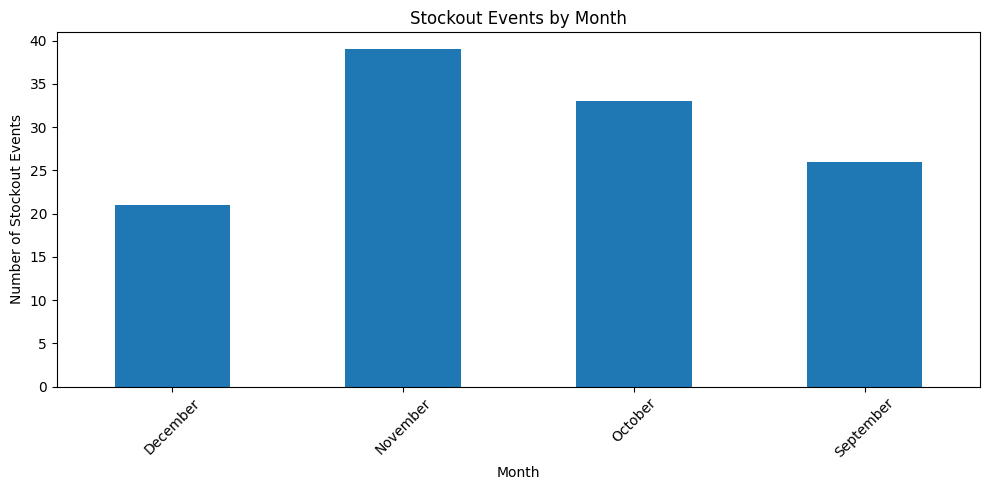

In [0]:
 import matplotlib.pyplot as plt

# Count stockout events by month
monthly_stockouts = (
    stockouts_clean.groupby("month")["stockout_id"]
    .nunique()
)

# Create the bar chart
plt.figure(figsize=(10, 5))

monthly_stockouts.plot(kind="bar")

plt.title("Stockout Events by Month")
plt.xlabel("Month")
plt.ylabel("Number of Stockout Events")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

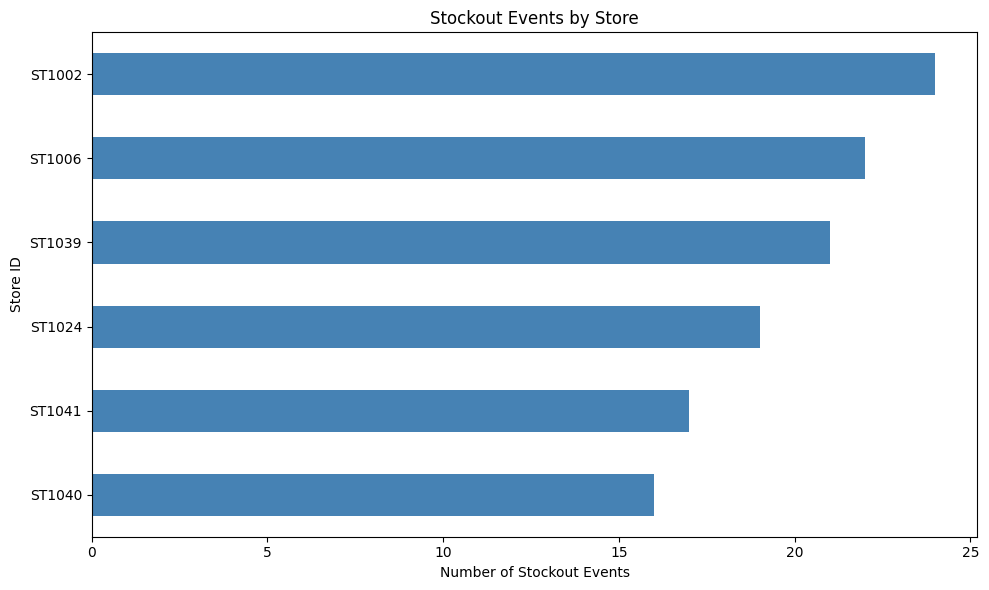

In [0]:
import matplotlib.pyplot as plt

# Count stockout events for each store
stockouts_by_store = (
    stockouts_clean.groupby("store_id")["stockout_id"]
    .nunique()
    .sort_values(ascending=True)
)

# Create horizontal bar chart
plt.figure(figsize=(10, 6))

stockouts_by_store.plot(
    kind="barh",
    color="steelblue"
)

plt.title("Stockout Events by Store")
plt.xlabel("Number of Stockout Events")
plt.ylabel("Store ID")

plt.tight_layout()
plt.show()

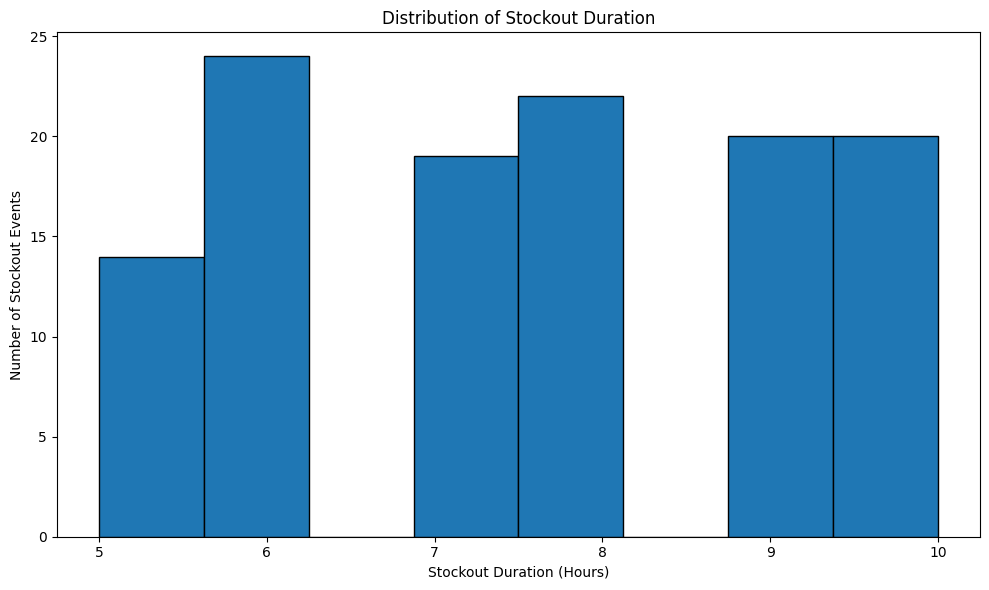

In [0]:
 import matplotlib.pyplot as plt

# Create histogram of stockout durations
plt.figure(figsize=(10, 6))

plt.hist(
    stockouts_clean["duration_hours"],
    bins=8,
    edgecolor="black"
)

plt.title("Distribution of Stockout Duration")
plt.xlabel("Stockout Duration (Hours)")
plt.ylabel("Number of Stockout Events")

plt.tight_layout()
plt.show()

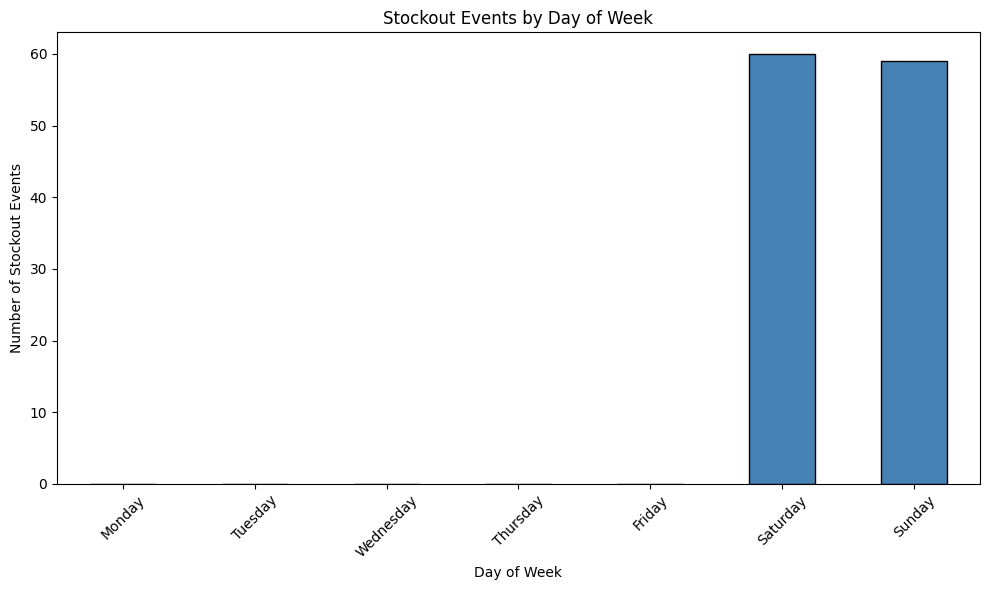

In [0]:
 import matplotlib.pyplot as plt

# Count stockout events by day of the week
stockouts_by_day = (
    stockouts_clean.groupby("day_of_week")["stockout_id"]
    .nunique()
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ])
)

# Create bar chart
plt.figure(figsize=(10, 6))

stockouts_by_day.plot(
    kind="bar",
    color="steelblue",
    edgecolor="black"
)

plt.title("Stockout Events by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Stockout Events")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()